In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Project data location
BASE_DIR = Path.cwd().parent
DATA_DIR = BASE_DIR / "data" / "raw"

# Load datasets
products = pd.read_csv(DATA_DIR / "products.csv")
suppliers = pd.read_csv(DATA_DIR / "suppliers.csv")
sales = pd.read_csv(DATA_DIR / "sales.csv", parse_dates=["sale_date"])
inventory = pd.read_csv(DATA_DIR / "inventory.csv")
purchases = pd.read_csv(DATA_DIR / "purchases.csv", parse_dates=["order_date"])

# Display configuration
pd.set_option("display.max_columns", None)
sns.set_theme(style="whitegrid")

print("All datasets loaded successfully!")

print("\nProducts:", products.shape)
print("Suppliers:", suppliers.shape)
print("Sales:", sales.shape)
print("Inventory:", inventory.shape)
print("Purchases:", purchases.shape)

sales.head()


All datasets loaded successfully!

Products: (50, 9)
Suppliers: (10, 4)
Sales: (36500, 9)
Inventory: (50, 4)
Purchases: (5048, 9)


,product_id,sale_date,units_sold,selling_price,revenue,cost,profit,promotion,stockout
0,1,2024-11-06,3,689.16,2067.48,1328.34,739.14,0,0
1,1,2024-11-07,3,689.16,2067.48,1328.34,739.14,1,0
2,1,2024-11-08,3,689.16,2067.48,1328.34,739.14,0,0
3,1,2024-11-09,3,689.16,2067.48,1328.34,739.14,0,0
4,1,2024-11-10,5,689.16,3445.80,2213.90,1231.90,0,0


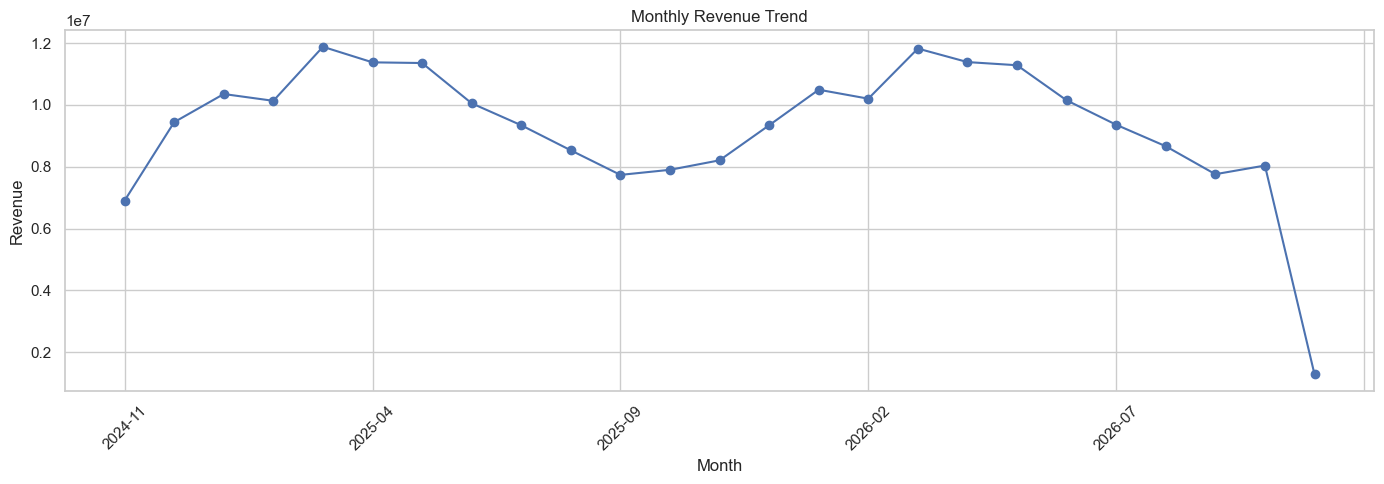

In [2]:

sales["month"] = sales["sale_date"].dt.to_period("M").astype(str)

monthly_revenue = sales.groupby("month")["revenue"].sum()

plt.figure(figsize=(14, 5))
monthly_revenue.plot(marker="o")

plt.title("Monthly Revenue Trend")
plt.xlabel("Month")
plt.ylabel("Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


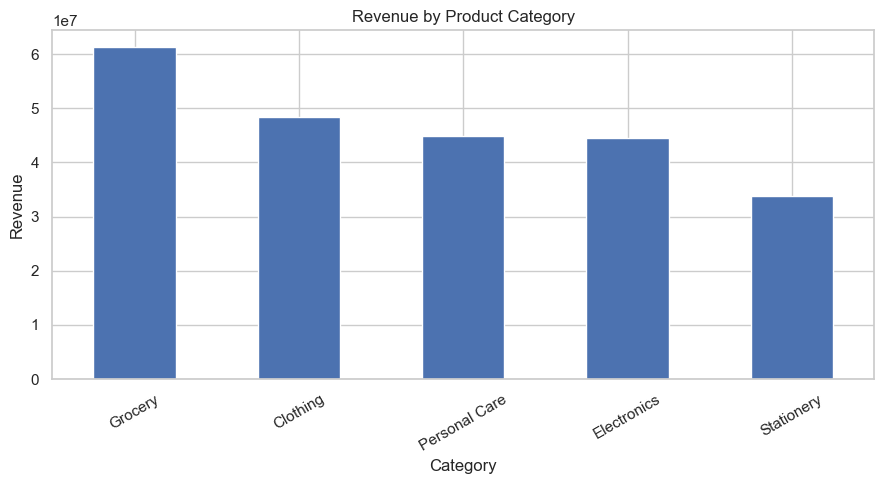

In [3]:

sales_products = sales.merge(
    products[["product_id", "category", "product_name"]],
    on="product_id",
    how="left"
)

category_revenue = sales_products.groupby(
    "category"
)["revenue"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
category_revenue.plot(kind="bar")

plt.title("Revenue by Product Category")
plt.xlabel("Category")
plt.ylabel("Revenue")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()


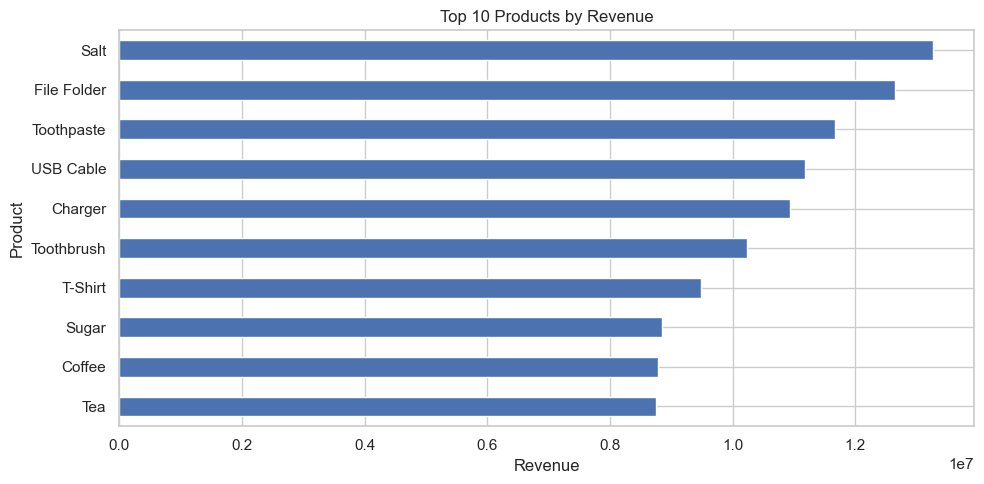

In [4]:

top_products = (
    sales_products.groupby("product_name")["revenue"]
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))
top_products.sort_values().plot(kind="barh")

plt.title("Top 10 Products by Revenue")
plt.xlabel("Revenue")
plt.ylabel("Product")
plt.tight_layout()
plt.show()


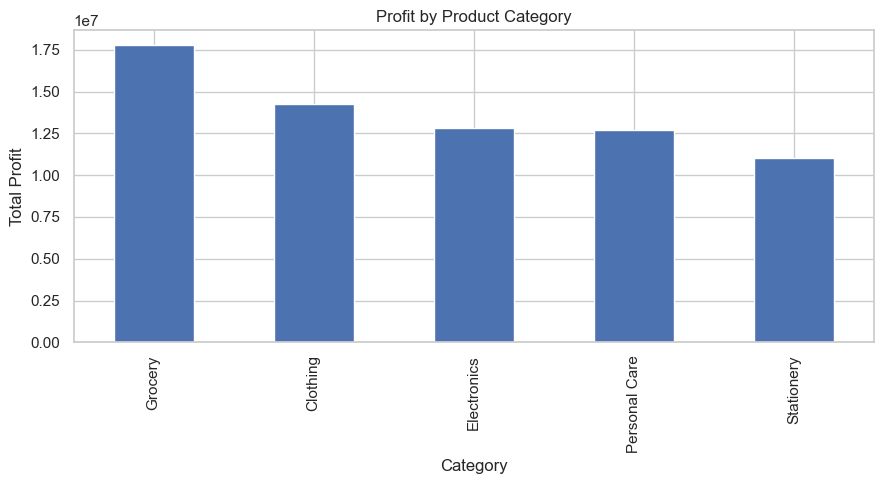

In [5]:

category_profit = sales_products.groupby(
    "category"
)["profit"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
category_profit.plot(kind="bar")

plt.title("Profit by Product Category")
plt.xlabel("Category")
plt.ylabel("Total Profit")
plt.tight_layout()
plt.show()


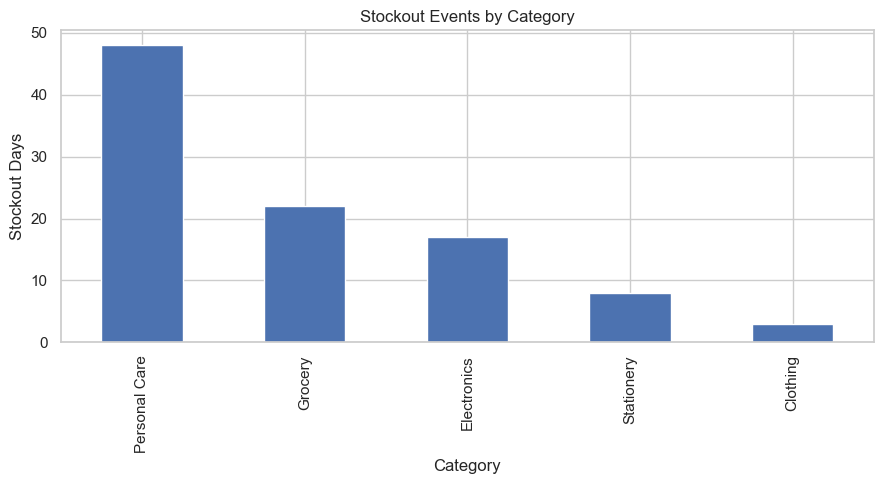

In [6]:

stockout_analysis = sales_products.groupby(
    "category"
)["stockout"].sum().sort_values(ascending=False)

plt.figure(figsize=(9, 5))
stockout_analysis.plot(kind="bar")

plt.title("Stockout Events by Category")
plt.xlabel("Category")
plt.ylabel("Stockout Days")
plt.tight_layout()
plt.show()


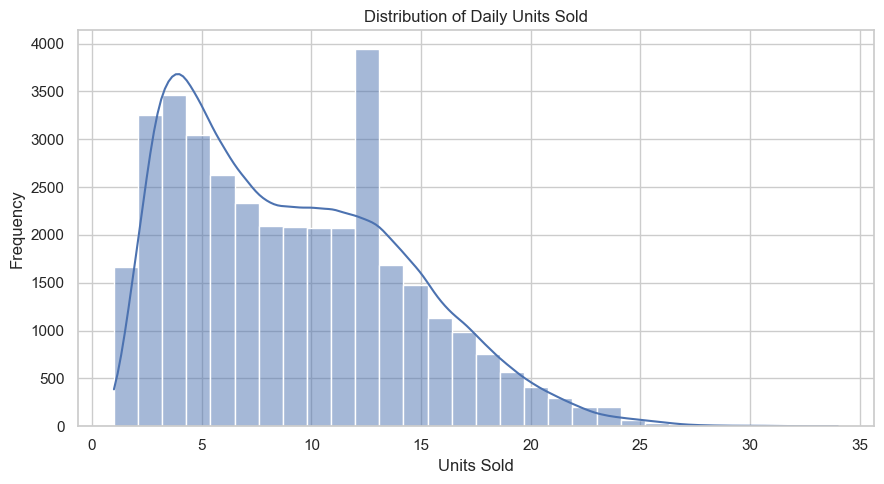

In [7]:

plt.figure(figsize=(9, 5))

sns.histplot(
    sales["units_sold"],
    bins=30,
    kde=True
)

plt.title("Distribution of Daily Units Sold")
plt.xlabel("Units Sold")
plt.ylabel("Frequency")
plt.tight_layout()
plt.show()


In [8]:

total_revenue = sales["revenue"].sum()
total_profit = sales["profit"].sum()
total_units = sales["units_sold"].sum()
total_stockouts = sales["stockout"].sum()

profit_margin = (
    total_profit / total_revenue * 100
    if total_revenue > 0 else 0
)

print("========== BUSINESS PERFORMANCE ==========")

print(f"Total Revenue: ₹{total_revenue:,.2f}")
print(f"Total Profit: ₹{total_profit:,.2f}")
print(f"Total Units Sold: {total_units:,}")
print(f"Total Stockout Events: {total_stockouts:,}")
print(f"Profit Margin: {profit_margin:.2f}%")
print(f"Number of Products: {products.shape[0]}")


========== BUSINESS PERFORMANCE ==========
Total Revenue: ₹233,020,521.02
Total Profit: ₹68,635,919.16
Total Units Sold: 334,476
Total Stockout Events: 98
Profit Margin: 29.45%
Number of Products: 50
